In [1]:
# mask-analog imports
import run_experiments as rexp
# create an Experiments object which allows you to access previous experiments and define new ones (and train a mask)
exp_object = rexp.Experiments('experiments.json')
import plot_analogs as pa
import plot_metrics as pm
import best_analogs as ba
import data_processing as dp
# hide some warnings that are not helpful
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
# make plots show up in the notebook
%matplotlib inline

# workflow for a new experiment

#### 1. preprocess data (saves data that is temporally and spatially smoothed)

#### 2. create the settings for a new experiment

#### 3. train (and plot) a mask based on the settings

#### 4. generate (or select a previously generated) analog library

#### 5. find the best analogs for a given state of interest (model, member)

#### 6. plot the results

### 1. preprocess data (saves data that is temporally and spatially smoothed)

In [2]:
# some good resolutions include:
# [0.9424083769633285, 1.25]
# [1.1120905585095784, 1.25]
# [1.3890301392687405, 1.40625]
# [1.8496375593391292, 1.875]
# [2.7672718509152645, 2.8125]

# var_list and model_list = -1 means use all available
# scratch means load the models and resolutions by reading the files directly (otherwise, use the version I hand put in there)

# uncomment and run this if you need something that is not already preprocessed -- will take a while (several hours)
# dp.preprocess_data(resolution, var_list=-1, model_list=-1, overwrite_data=False, scratch=False)

### 2. create the settings for a new experiment

In [2]:
# print out the settings
# print(exp_object.make_exp_dictionary.__doc__)
# print('---------------------------------------------------------')
# these are all the available models and variables in the raw_data directory
# exp_object.list_variables
# print('---------------------------------------------------------')
# this lists all the regions available (you can add new regions to regions.json)
# exp_object.list_regions

In [6]:
experiment_name = "base_nodense_2.8_lt1"
all_models = ['GISS-E2-2-G', 'NorESM2-LM', 'ACCESS-ESM1-5', 'CanESM5-1', 'CMCC-CM2-HR4', 'CESM2', 'AWI-ESM-1-1', 'CAMS-CSM1', 'CMCC-ESM2', 'CESM2-WACCM', 'MPI-ESM1-2-HR', 'AWI-CM-1-1', 'MIROC', 'MPI-ESM1-2-LR', 'GISS-E2-1-G', 'CNRM-CM6-1', 'CMCC-CM2-SR5', 'MRI-ESM2-0', 'MIROC-ES2H', 'CanESM5-CanOE', 'ACCESS-CM2', 'BCC-ESM1', 'UKESM1-1-LL', 'UKESM1-0-LL', 'CanESM5', 'BCC-CSM2', 'TaiESM', 'NorESM2-MM', 'MIROC-ES2L']
obs = ['ERA5', 'BEST']

In [ ]:
# now, define a new experiment with all the settings you want to change
new_exp = exp_object.make_exp_dictionary(experiment_name, variable_list=['tas'], analog_models=all_models, soi_models=all_models, leadtime=5, split=[5, 3, 2], region='western us', val_models=all_models, target_var=['tas'], window=False, trajectory=1, resolutions=4, time_range=False, norm_data=True, baseline=[1961, 1990], remove_trend=False, norm_weights=True, transfer_exp=None, mask=False, prediction_nodes=[], prediction_activation='elu', learning_rate=0.001, loss='mse', patience=50, min_delta=0.005, batch_size=64, val_batch_size=2500, max_epochs=5000, mask_activation='relu', mask_init="ones", mask_l1=0.0, mask_l2=0.0, seed=20)

# this adds the experiment to the json file
exp_object.add_experiment(new_exp)

experiment_settings are:
{'base_nodense': {'experiment_name': 'base_nodense', 'variable_list': ['tas'], 'analog_models': ['GISS-E2-2-G', 'NorESM2-LM', 'ACCESS-ESM1-5', 'CanESM5-1', 'CMCC-CM2-HR4', 'CESM2', 'AWI-ESM-1-1', 'CAMS-CSM1', 'CMCC-ESM2', 'CESM2-WACCM', 'MPI-ESM1-2-HR', 'AWI-CM-1-1', 'MIROC', 'MPI-ESM1-2-LR', 'GISS-E2-1-G', 'CNRM-CM6-1', 'CMCC-CM2-SR5', 'MRI-ESM2-0', 'MIROC-ES2H', 'CanESM5-CanOE', 'ACCESS-CM2', 'BCC-ESM1', 'UKESM1-1-LL', 'UKESM1-0-LL', 'CanESM5', 'BCC-CSM2', 'TaiESM', 'NorESM2-MM', 'MIROC-ES2L'], 'soi_models': ['GISS-E2-2-G', 'NorESM2-LM', 'ACCESS-ESM1-5', 'CanESM5-1', 'CMCC-CM2-HR4', 'CESM2', 'AWI-ESM-1-1', 'CAMS-CSM1', 'CMCC-ESM2', 'CESM2-WACCM', 'MPI-ESM1-2-HR', 'AWI-CM-1-1', 'MIROC', 'MPI-ESM1-2-LR', 'GISS-E2-1-G', 'CNRM-CM6-1', 'CMCC-CM2-SR5', 'MRI-ESM2-0', 'MIROC-ES2H', 'CanESM5-CanOE', 'ACCESS-CM2', 'BCC-ESM1', 'UKESM1-1-LL', 'UKESM1-0-LL', 'CanESM5', 'BCC-CSM2', 'TaiESM', 'NorESM2-MM', 'MIROC-ES2L'], 'leadtime': 5, 'split': {'analog': 5, 'training': 3, 

### 3. train (and plot) a mask based on the settings

In [2]:
# NOTE: this may need to be run in a terminal when the amount of data is large
experiment_name = "wus_lt1_test_flat_target"
exp_object.make_mask(experiment_name, overwrite_model=True, overwrite_mask=True)

loading variables: tas
from models: GISS-E2-2-G NorESM2-LM ACCESS-ESM1-5 CanESM5-1 CMCC-CM2-HR4 CESM2 AWI-ESM-1-1 CAMS-CSM1 CMCC-ESM2 CESM2-WACCM MPI-ESM1-2-HR AWI-CM-1-1 MIROC MPI-ESM1-2-LR GISS-E2-1-G CNRM-CM6-1 CMCC-CM2-SR5 MRI-ESM2-0 MIROC-ES2H CanESM5-CanOE ACCESS-CM2 BCC-ESM1 UKESM1-1-LL UKESM1-0-LL CanESM5 BCC-CSM2 TaiESM NorESM2-MM MIROC-ES2L
found preprocessed data for GISS-E2-2-G
more members requested than available. requested: 5, available: 3
using 3 members from NorESM2-LM
found preprocessed data for NorESM2-LM
found preprocessed data for ACCESS-ESM1-5
found preprocessed data for CanESM5-1
more members requested than available. requested: 5, available: 1
using 1 members from CMCC-CM2-HR4
found preprocessed data for CMCC-CM2-HR4
found preprocessed data for CESM2
more members requested than available. requested: 5, available: 1
using 1 members from AWI-ESM-1-1
found preprocessed data for AWI-ESM-1-1
more members requested than available. requested: 5, available: 3
using 3 me

<xarray.Dataset>
Dimensions:  (lat: 65, lon: 128)
Coordinates:
  * lat      (lat) float32 -88.62 -85.85 -83.08 -80.31 ... 82.95 85.72 88.49
  * lon      (lon) float32 0.0 2.812 5.625 8.438 ... 348.8 351.6 354.4 357.2
Data variables:
    tas      (lat, lon) float32 9.01e-05 8.955e-05 ... 7.902e-05 7.936e-05

In [2]:
experiment_name = "wus_lt5"

# plot the mask
# exp_object.plot_mask(experiment_name, colorbar=False)
# make a gif of the training
exp_object.make_mask_gif(experiment_name)

### 4. generate (or select a previously generated) analog library

In [13]:
# model_list is to set the models in the library, n_members sets how many (-1 uses all)
# library_name can be the name of a previous experiment and will use that library
library = ba.BestAnalogs(experiment_name, library_name=None, model_list=all_models+['BEST'], n_members=-1)

loading all available members, using 11 members from model: GISS-E2-2-G
loading variables: tas
from models: GISS-E2-2-G
found preprocessed data for GISS-E2-2-G
#################################################################
processing GISS-E2-2-G input dataset
#################################################################
baselining on [1961, 1990] for variables: tas
-------------------------------------------------------
-------------------------------------------------------
#################################################################
processing GISS-E2-2-G target dataset
#################################################################
extracting region(s): western us
western us found in regions.json
-------------------------------------------------------
baselining on [1961, 1990] for variables: tas
-------------------------------------------------------
-------------------------------------------------------
loading all available members, using 3 members from model: NorE

### 5. find the best analogs for a given state of interest (model, member)

In [14]:
# this ranks the analogs in the library for this SOI
# this may also need to be run in the terminal
tether = 5
soi_model = 'BEST'
soi_member = 0
library = ba.BestAnalogs(experiment_name)
library.get_all_soi_analogs(soi_model, soi_member, tether=tether, savename=None, quant=None, mask_type='weights', leadtime=None)
library.get_all_soi_analogs(soi_model, soi_member, tether=tether, savename='t5_global', quant=None, mask_type='global', leadtime=None)
library.get_all_soi_analogs(soi_model, soi_member, tether=tether, savename='t5_regional', quant=None, mask_type='regional', leadtime=None)

previously saved analogs:
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/base_nodense_2.8_iesms/BEST_mem0_teth5.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/base_nodense_2.8_iesms/t5_global.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/base_nodense_2.8_iesms/t5_regional.pickle


### 6. plot the results

In [14]:
# suite of plots
# experiment_name = 'earlystopmodel_deep'
tether = 1
soi_model = 'BEST'
soi_member = 0
library = pa.PlotAnalogs(experiment_name, soi_model, soi_member, tether, 'tas', library_name='base_dense_2.8', fig_path=None)

loaded analog library from experiment called: base_dense_2.8
previously saved analogs: BEST_mem0_teth1_library_base_dense_2.8 t3_addregional t3_quant_0.2 t3_quant_0.4 t3_quant_0.6 t3_quant_0.8 t5_quant_0.2 t5_quant_0.4 t5_quant_0.6 t5_quant_0.8 tether_1 tether_10 tether_2 tether_3 tether_4 tether_5
loaded analogs for BEST_mem0_teth1_library_base_dense_2.8


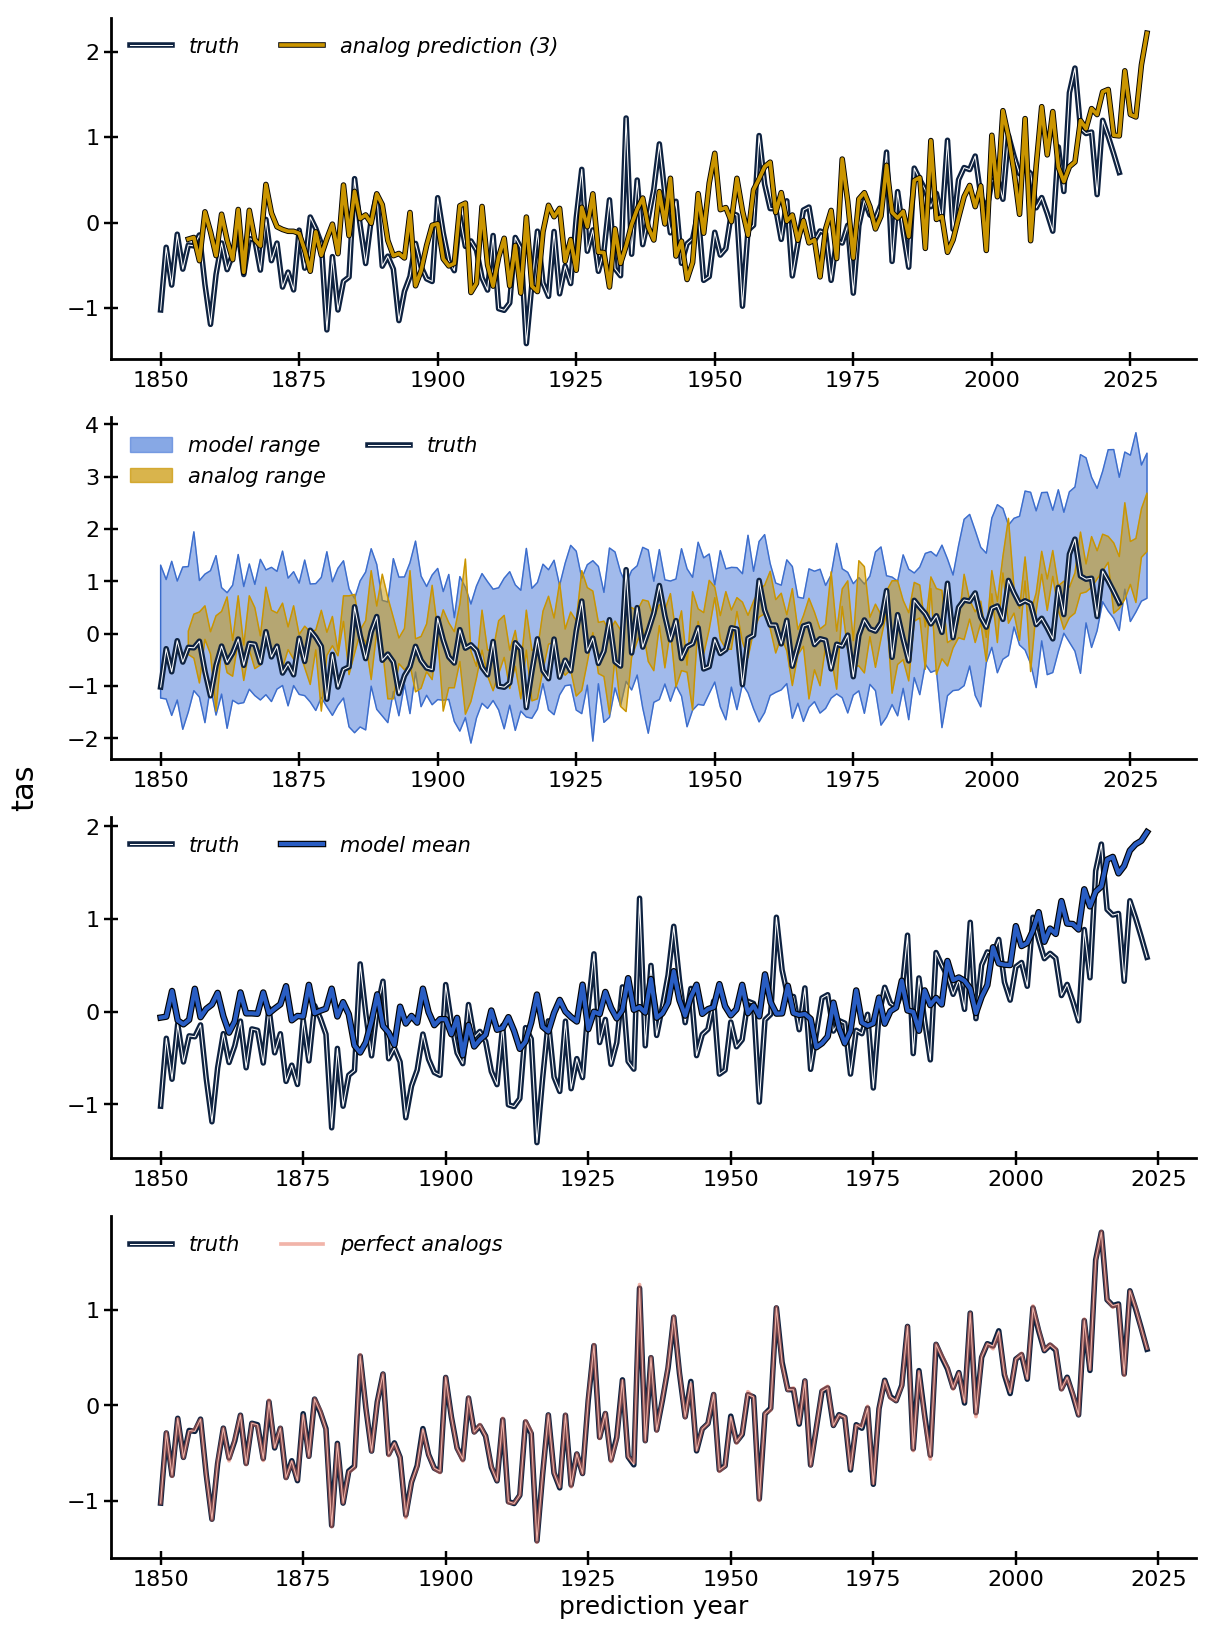

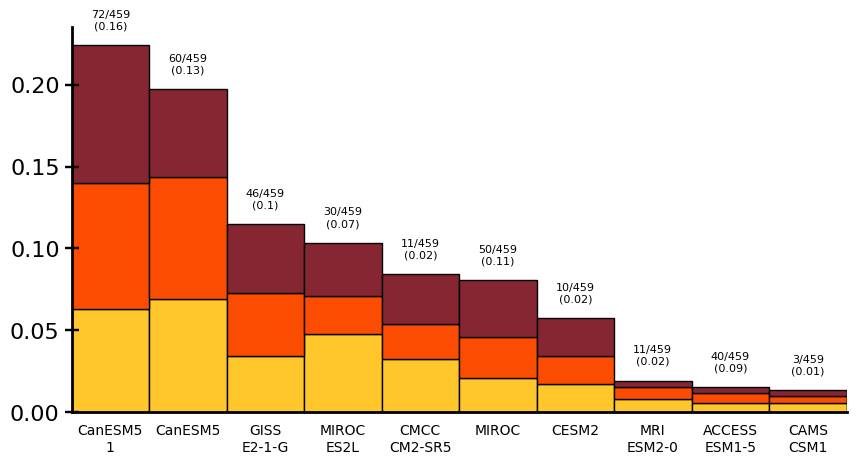

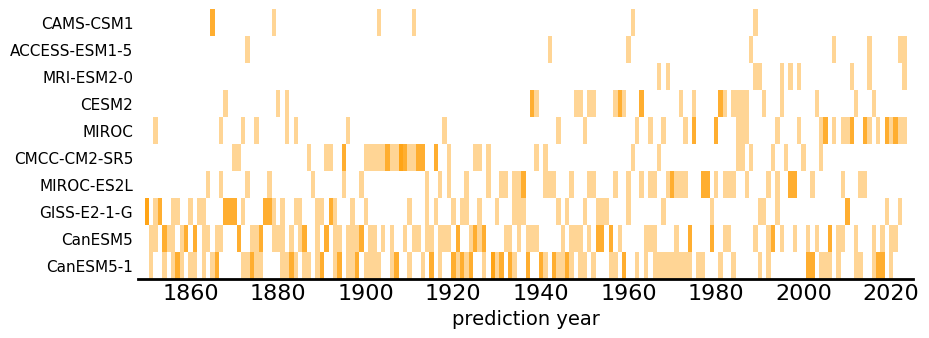

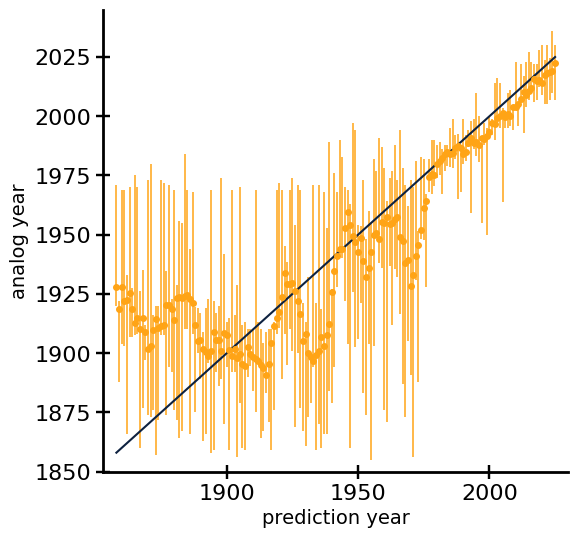

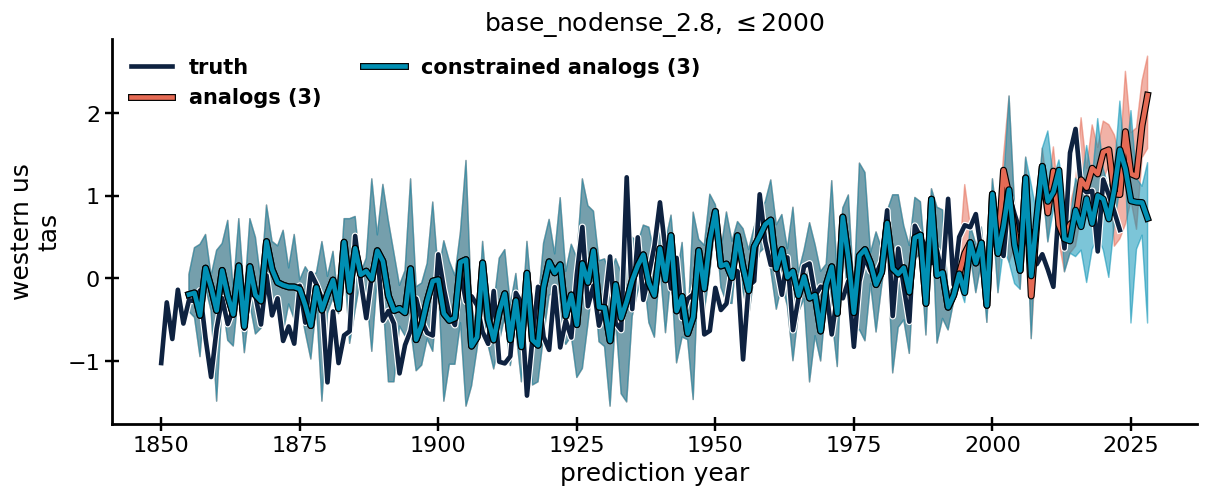

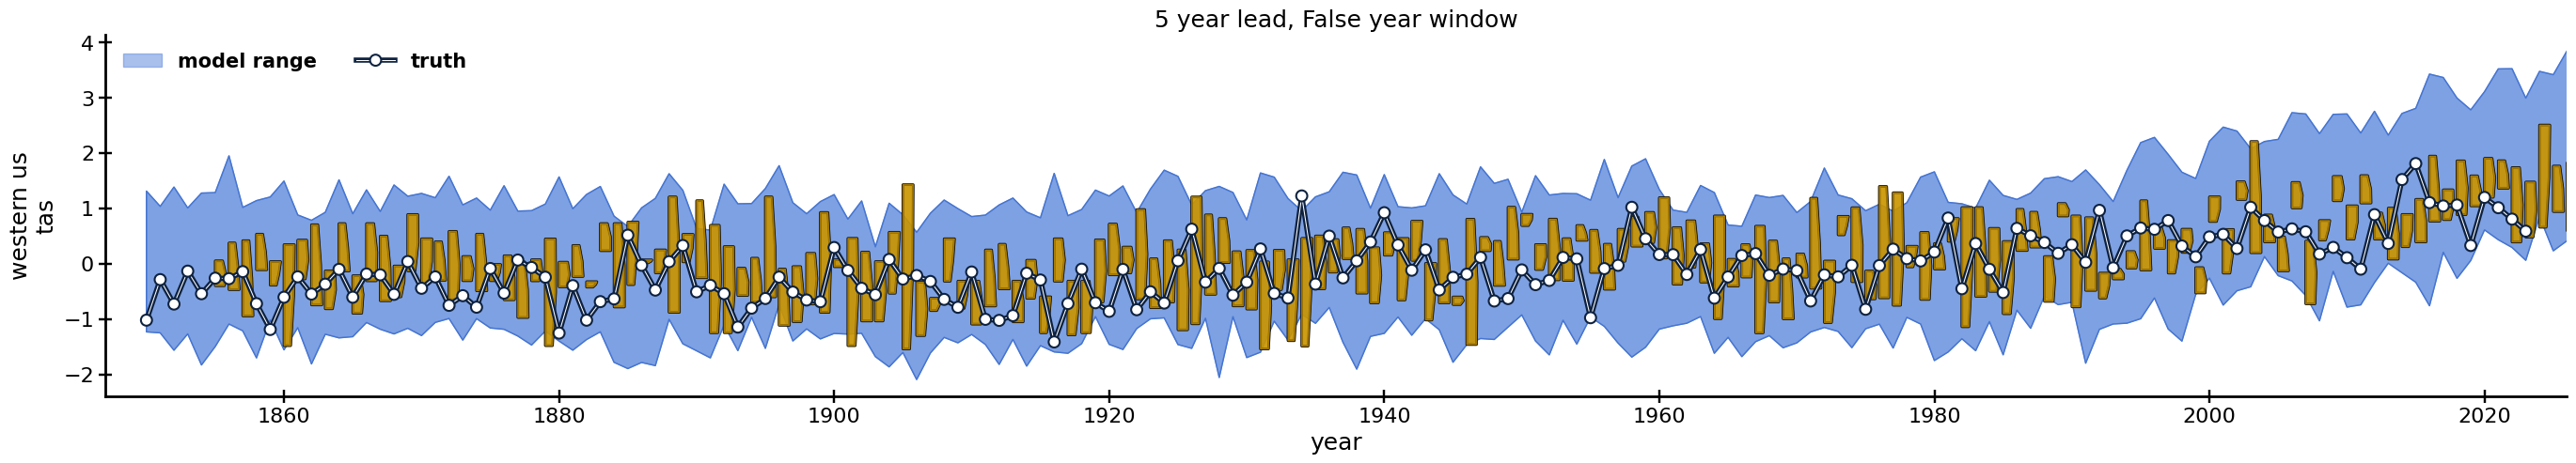

In [21]:
n_analogs = 3
roll_years = 7
max_year = 2000

# plot prediction, library range, model mean, perfect analogs
library.plot_prediction_suite(n_analogs, time_range=None, savename=None)
# here is the distribution of how often each model was picked as a top 10 analog
library.plot_model_distribution(n_analogs, time_range=None, savename=None)
# or plot how often each model is picked as a function of time
library.plot_model_times(n_analogs, time_range=None, savename=None)
# plot the selected years versus predicted year
library.plot_selected_times(n_analogs, roll_years, time_range=None, savename=None)
# plot prediction constrained to only select analogs from early than max_year
library.plot_constrained_prediction(n_analogs, max_year, time_range=None, savename=None)
# plot the prediction as a distribution
library.plot_dist_prediction(n_analogs, savename=None, time_range=None)

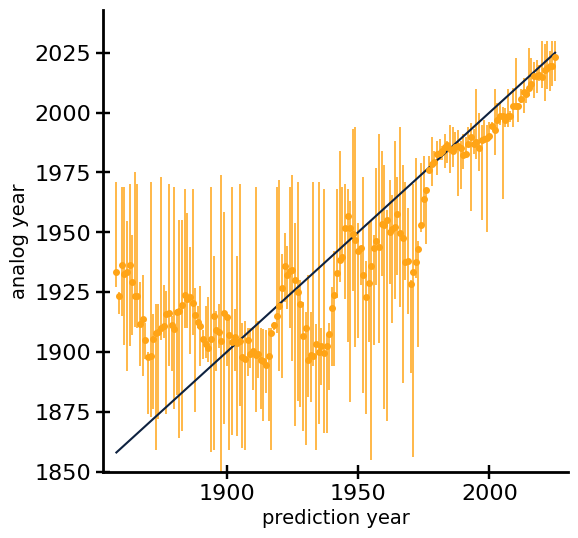

In [15]:
n_analogs = 2
roll_years = 7

# plot the selected years versus predicted year
library.plot_selected_times(n_analogs, roll_years, time_range=None, savename=None)

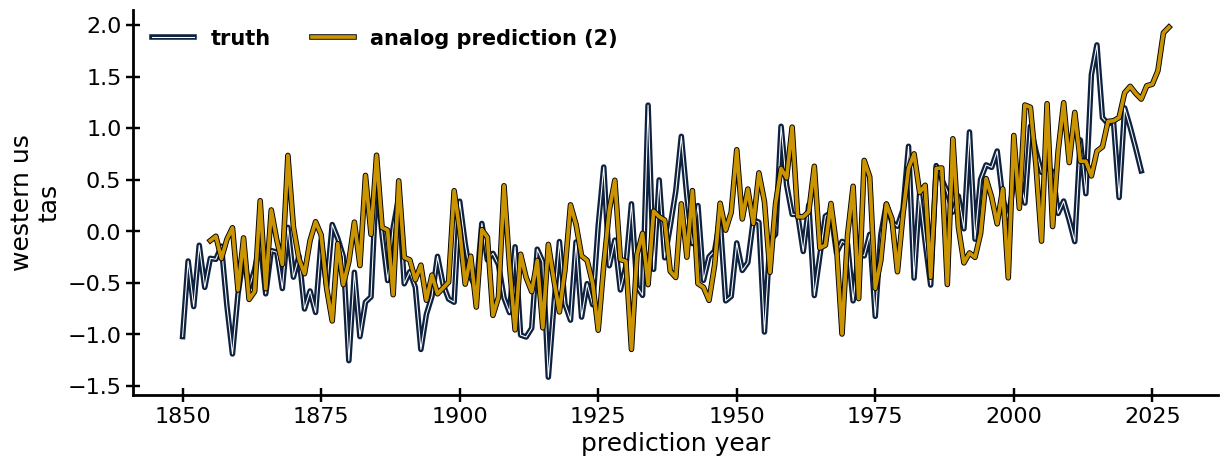

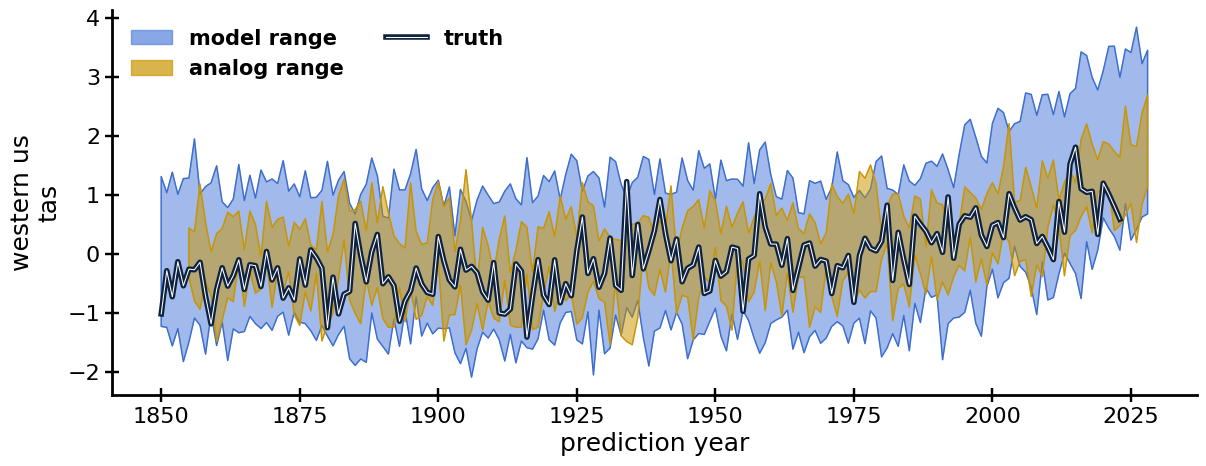

In [16]:
library.plot_prediction(2, time_range=None, savename=None)
library.plot_range(5, time_range=None, savename=None)

In [4]:
tether = 1
soi_model = 'BEST'
soi_member = 0
metric_plots = pm.PlotMetrics(experiment_name, soi_model, soi_member, tether, 'tas', leadtime=5, library_name='base_dense_2.8', fig_path=None)

loaded analog library from experiment called: base_dense_2.8
previously saved analogs: BEST_mem0_teth1_library_base_dense_2.8 t3_addregional t3_quant_0.2 t3_quant_0.4 t3_quant_0.6 t3_quant_0.8 t5_quant_0.2 t5_quant_0.4 t5_quant_0.6 t5_quant_0.8 tether_1 tether_10 tether_2 tether_3 tether_4 tether_5
using analogs from BEST_mem0_teth1_library_base_dense_2.8


/Users/mafern/Desktop/mask-analog-projections/plot_metrics.py:215: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


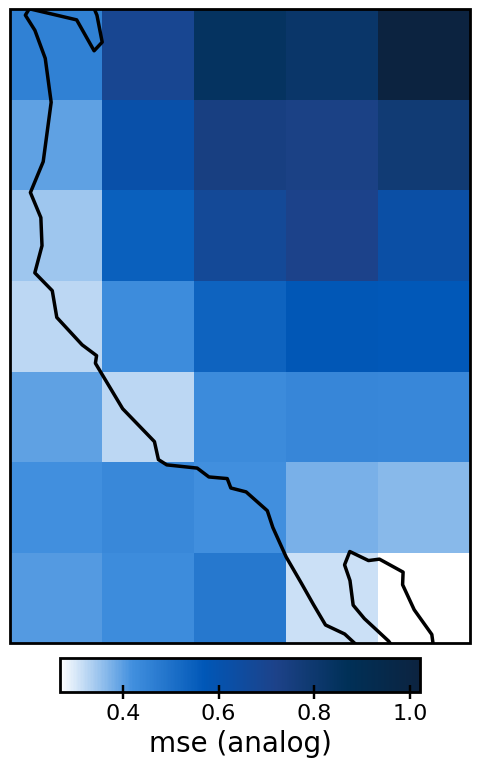

In [11]:
n_analogs = 2
metric_plots.map_mse(n_analogs, prediction="analog", savename=None, time_range=None, align=False)

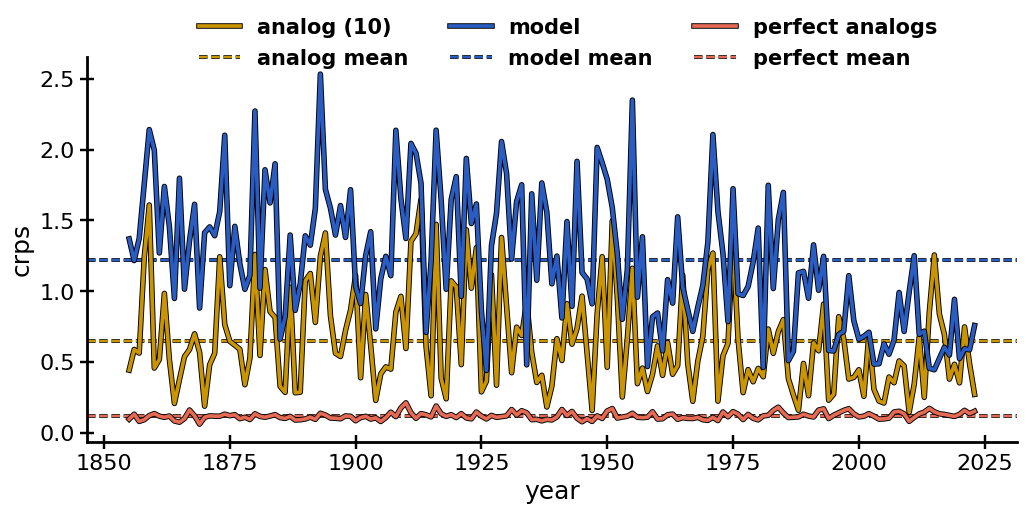

/Users/mafern/Desktop/mask-analog-projections/plot_metrics.py:713: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


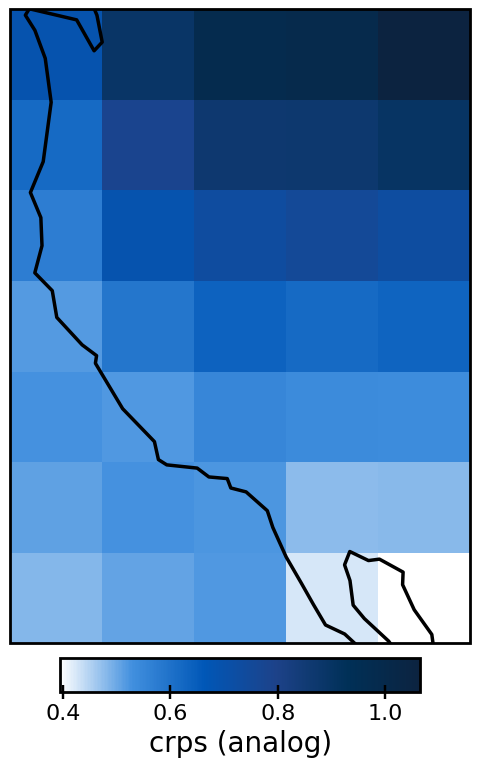

In [8]:
n_analogs = 10
metric_plots.time_crps(n_analogs, savename=None, time_range=None)
metric_plots.map_crps(n_analogs, prediction="analog", savename=None, time_range=None, align=False)